In [1]:
# Step 1: Import Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load Dataset
housing = fetch_california_housing(as_frame=True)

df = housing.frame.copy()

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset Loaded Successfully!
Dataset Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [2]:
# Step 2: Explore Dataset

print("Column Names:")
print(df.columns.tolist())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Column Names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Dataset Shape:
(20640, 9)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Statistical Summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [3]:
# Step 3: Data Cleaning

print("Missing Values Before Cleaning:")
print(df.isnull().sum())

print("\nDuplicate Rows Before Cleaning:")
print(df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Remove rows with missing values
df = df.dropna().copy()

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nDuplicate Rows After Cleaning:")
print(df.duplicated().sum())

print("\nFinal Dataset Shape:")
print(df.shape)

Missing Values Before Cleaning:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Duplicate Rows Before Cleaning:
0

Missing Values After Cleaning:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Duplicate Rows After Cleaning:
0

Final Dataset Shape:
(20640, 9)


In [4]:
# Step 4: Select Features and Target

# Target variable
y = df["MedHouseVal"].copy()

# Input features
X = df.drop("MedHouseVal", axis=1).copy()

# Feature Engineering
X["RoomsPerHousehold"] = (
    X["AveRooms"] / X["AveOccup"].clip(lower=0.01)
)

X["BedroomsPerRoom"] = (
    X["AveBedrms"] / X["AveRooms"].clip(lower=0.01)
)

X["PopulationPerHousehold"] = (
    X["Population"] / X["AveOccup"].clip(lower=0.01)
)

print("Features:")
print(X.columns.tolist())

print("\nTarget Variable: MedHouseVal")
print("Number of Features:", X.shape[1])
print("Number of Target Values:", y.shape[0])

display(X.head())

Features:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'RoomsPerHousehold', 'BedroomsPerRoom', 'PopulationPerHousehold']

Target Variable: MedHouseVal
Number of Features: 11
Number of Target Values: 20640


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,RoomsPerHousehold,BedroomsPerRoom,PopulationPerHousehold
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,2.732919,0.146591,126.0
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,2.956685,0.155797,1138.0
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,2.957661,0.129516,177.0
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,2.283154,0.184458,219.0
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,2.879646,0.172096,259.0


In [5]:
# Step 5: Split Dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (16512, 11)
Testing Features: (4128, 11)
Training Target: (16512,)
Testing Target: (4128,)


In [6]:
# Step 6: Create Model Pipeline

model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

# Train Model
model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [7]:
# Step 7: Train Baseline Model

baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

print("Baseline Model Trained Successfully!")
print("Baseline predicts the training target mean.")

Baseline Model Trained Successfully!
Baseline predicts the training target mean.


In [8]:
# Step 8: Evaluate Both Models

# Predictions
y_pred = model.predict(X_test)

# Linear Regression Metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Baseline Metrics
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_pred)
)
baseline_r2 = r2_score(y_test, baseline_pred)

# Comparison Table
results = pd.DataFrame({
    "Model": ["Baseline (Mean)", "Linear Regression"],
    "MAE": [baseline_mae, mae],
    "RMSE": [baseline_rmse, rmse],
    "R2 Score": [baseline_r2, r2]
})

print("MODEL PERFORMANCE COMPARISON")
display(results.round(4))

MODEL PERFORMANCE COMPARISON


,Model,MAE,RMSE,R2 Score
0,Baseline (Mean),0.9061,1.1449,-0.0002
1,Linear Regression,0.4874,0.6738,0.6535


In [17]:
from google.colab import files
files.download("model_evaluation_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
# Step 9: 5-Fold Cross-Validation

cv_scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=5,
    scoring="neg_root_mean_squared_error"
)

cv_rmse = -cv_scores

print("Cross-Validation RMSE Scores:")
print(np.round(cv_rmse, 4))

print("\nMean CV RMSE:", round(cv_rmse.mean(), 4))
print("Standard Deviation:", round(cv_rmse.std(), 4))


Cross-Validation RMSE Scores:
[0.6693 0.655  0.6658 0.6634 0.7192]

Mean CV RMSE: 0.6745
Standard Deviation: 0.0228


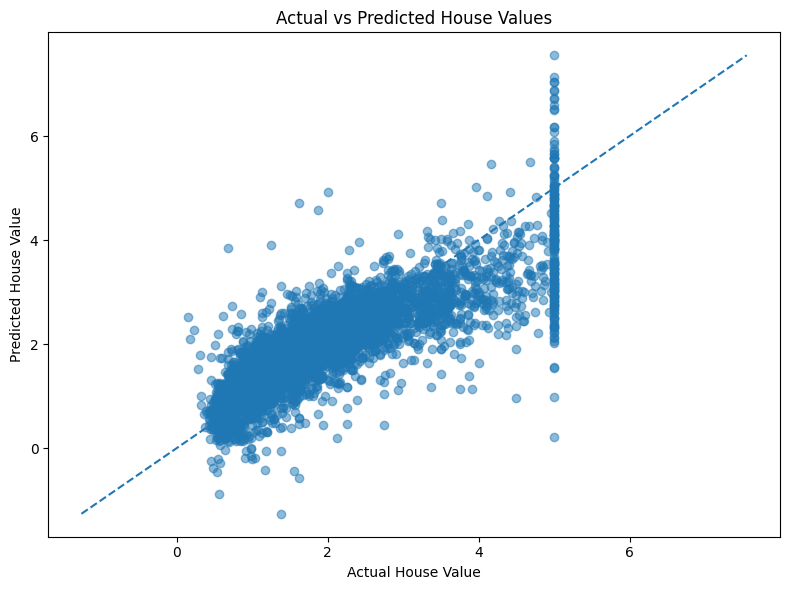

In [10]:
# Step 10: Actual vs Predicted Plot

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Actual vs Predicted House Values")
plt.tight_layout()
plt.show()

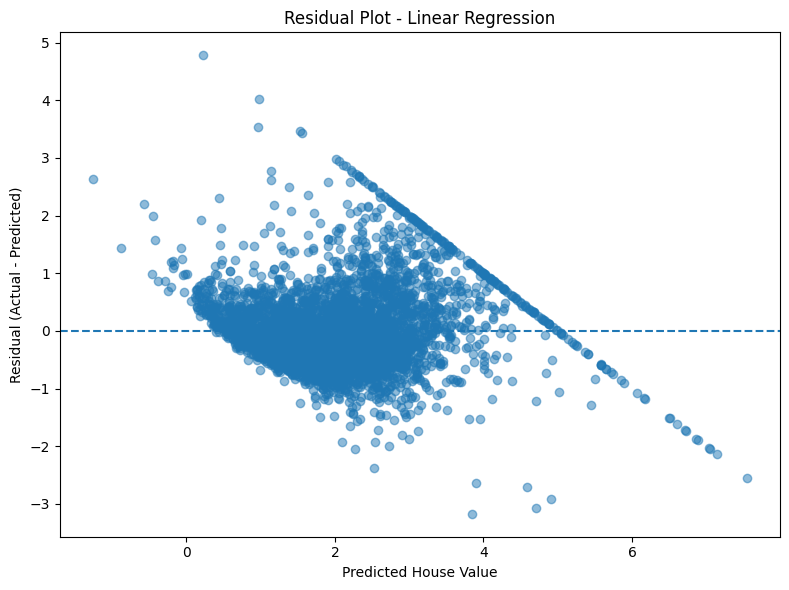

In [11]:
# Step 11: Residual Plot

residuals = y_test - y_pred

plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted House Value")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot - Linear Regression")

plt.tight_layout()
plt.show()

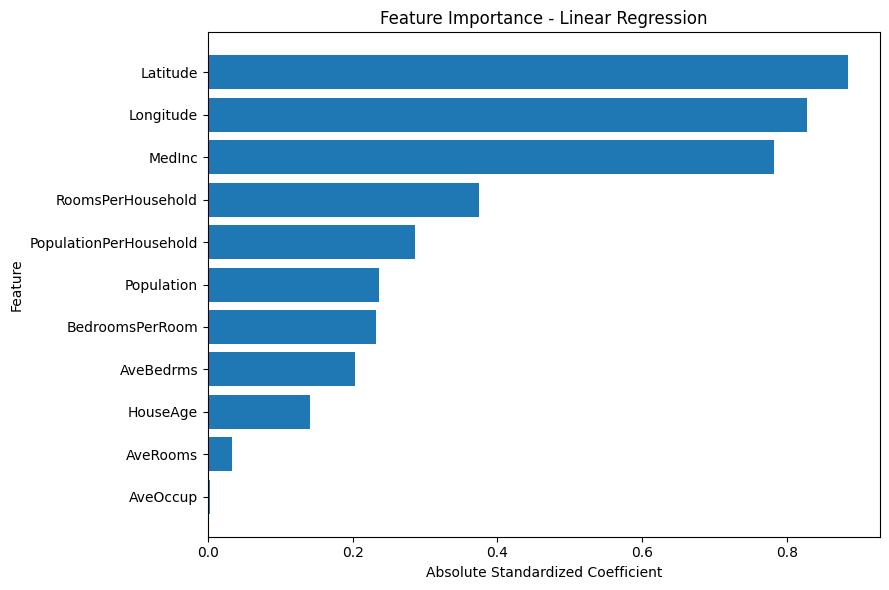

Feature Coefficients and Importance:


,Feature,Coefficient,Absolute Importance
6,Latitude,-0.8840,0.8840
7,Longitude,-0.8271,0.8271
0,MedInc,0.7817,0.7817
8,RoomsPerHousehold,0.3743,0.3743
10,PopulationPerHousehold,0.2867,0.2867
4,Population,-0.2366,0.2366
9,BedroomsPerRoom,0.2325,0.2325
3,AveBedrms,-0.2028,0.2028
1,HouseAge,0.1409,0.1409
2,AveRooms,-0.0337,0.0337


Intercept: 2.0719


In [12]:
# Step 12: Feature Importance

regressor = model.named_steps["regressor"]

importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": regressor.coef_,
    "Absolute Importance": np.abs(regressor.coef_)
})

importance = importance.sort_values(
    "Absolute Importance",
    ascending=True
)

plt.figure(figsize=(9, 6))

plt.barh(
    importance["Feature"],
    importance["Absolute Importance"]
)

plt.xlabel("Absolute Standardized Coefficient")
plt.ylabel("Feature")
plt.title("Feature Importance - Linear Regression")

plt.tight_layout()
plt.show()

print("Feature Coefficients and Importance:")
display(
    importance.sort_values(
        "Absolute Importance",
        ascending=False
    ).round(4)
)

print("Intercept:", round(regressor.intercept_, 4))

In [13]:
# Step 13: Compare First 10 Predictions

comparison = pd.DataFrame({
    "Actual House Value": y_test.iloc[:10].values,
    "Predicted House Value": y_pred[:10]
})

comparison["Absolute Error"] = np.abs(
    comparison["Actual House Value"]
    - comparison["Predicted House Value"]
)

display(comparison.round(4))

,Actual House Value,Predicted House Value,Absolute Error
0,0.477,0.4990,0.0220
1,0.458,1.7487,1.2907
2,5.000,3.4618,1.5382
3,2.186,2.6234,0.4374
4,2.780,2.6587,0.1213
5,1.587,2.0228,0.4358
6,1.982,2.5428,0.5608
7,1.575,1.9085,0.3335
8,3.400,2.9460,0.4540
9,4.466,3.9392,0.5268


In [18]:
from google.colab import files
files.download("feature_importance.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
# Step 14: Predict House Values

sample_houses = X_test.iloc[:3]

sample_predictions = model.predict(sample_houses)

print("Example House Predictions:")

for i, price in enumerate(sample_predictions, start=1):
    print(
        f"House {i}: {price:.4f} "
        f"(approximately ${price * 100000:,.0f})"
    )

Example House Predictions:
House 1: 0.4990 (approximately $49,903)
House 2: 1.7487 (approximately $174,869)
House 3: 3.4618 (approximately $346,177)


In [15]:
# Step 15: Save Model

joblib.dump(
    model,
    "house_price_prediction_model.pkl"
)

# Save evaluation comparison
results.to_csv(
    "model_evaluation_results.csv",
    index=False
)

# Save feature importance
importance.to_csv(
    "feature_importance.csv",
    index=False
)

print("Model saved successfully!")
print("Evaluation results saved successfully!")
print("Feature importance saved successfully!")

print("\n========== FINAL PROJECT RESULTS ==========")
print("Project: House Price Prediction")
print("Algorithm: Linear Regression")
print("Baseline RMSE:", round(baseline_rmse, 4))
print("Linear Regression MAE:", round(mae, 4))
print("Linear Regression RMSE:", round(rmse, 4))
print("Linear Regression R2 Score:", round(r2, 4))
print("Mean Cross-Validation RMSE:", round(cv_rmse.mean(), 4))
print("===========================================")

Model saved successfully!
Evaluation results saved successfully!
Feature importance saved successfully!

========== FINAL PROJECT RESULTS ==========
Project: House Price Prediction
Algorithm: Linear Regression
Baseline RMSE: 1.1449
Linear Regression MAE: 0.4874
Linear Regression RMSE: 0.6738
Linear Regression R2 Score: 0.6535
Mean Cross-Validation RMSE: 0.6745
